# Cross-validation diagram: presentation theme

Matches the deck: an ocean-blue background, white Inter Bold text, and light steel-blue boxes like the Methodology slide, with coral orange for test.
Every segment has a navy outline, and each fold row has a white border.

- `BACKGROUND = 'transparent'` lets the slide photo show through (recommended); `'navy'` gives a solid deck-blue background.
- The Inter font is loaded from `fonts/` next to the notebook (falls back to DejaVu Sans if it's missing).
- Uses the real fold assignment (1,462 frames; 15-frame buffer either side of test).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle

BACKGROUND = 'transparent'   # 'transparent' or 'navy'
HEIGHT = None                # inches; None = as short as possible. Width is 13.33
SHOW_FOLD_LABELS = True
SAVE = True
DPI = 200

# deck colours
NAVY = '#0a3358'             # slide background blue
WHITE = '#ffffff'
EDGE = '#0b2545'             # outline between segments
COL = {'train': '#c9d6e2',   # light steel blue (like the Methodology boxes)
       'val': '#5aa9e6',     # sky blue
       'test': '#f26d3d',    # coral orange (matches the orange in the results charts)
       'buffer': '#7d93ab'}  # slate

# font
FONT = 'DejaVu Sans'
for w in ('400', '700'):
    p = os.path.join('fonts', f'Inter-{w}.ttf')
    if os.path.exists(p):
        font_manager.fontManager.addfont(p); FONT = 'Inter'
plt.rcParams.update({'font.family': FONT})
print('font:', FONT)

font: Inter


In [2]:
BLOCK_FOLD = [3, 1, 2, 2, 4, 3, 0, 1, 3, 3, 1, 1, 2, 3, 3, 2, 0, 1, 0, 0, 4, 0, 1, 3, 0, 4, 2, 1, 1, 3, 1, 0, 4, 3,
              3, 4, 0, 4, 2, 4, 4, 2, 1, 0, 2, 2, 0, 2, 4]          # fold (0-based) of each 30-frame block
FRAMES = np.arange(1000, 2462); BLOCK = (FRAMES - 1000) // 30; NB = len(BLOCK_FOLD); BUFFER = 15
FOLD_OF = np.array([BLOCK_FOLD[b] for b in BLOCK])

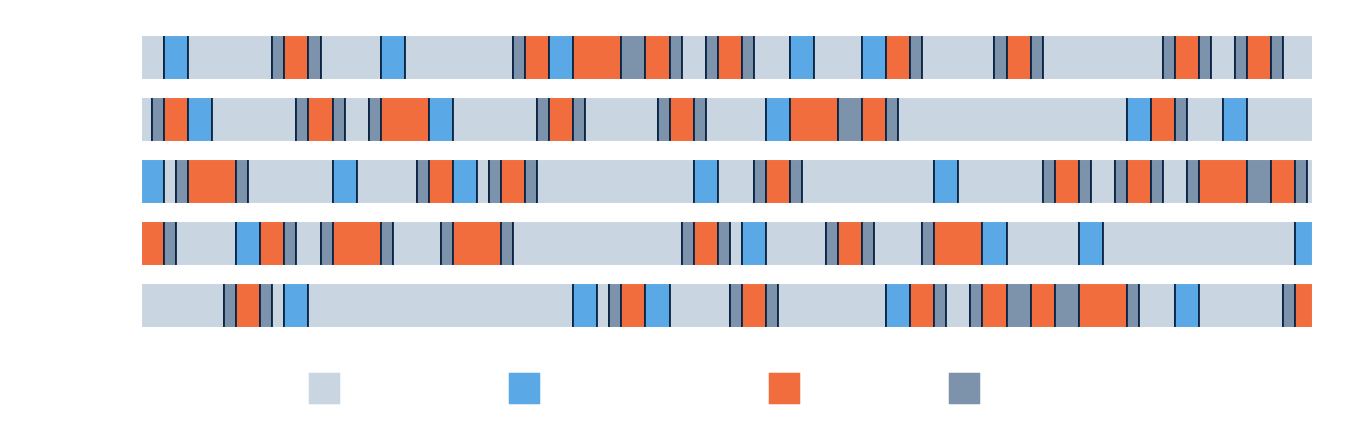

In [3]:
W = 13.33
rh, gap, key_h = 0.46, 0.16, 0.6
rows_h = 5 * rh + 4 * gap
need = 0.25 + rows_h + 0.3 + key_h
H = max(HEIGHT or 0, need)
fig = plt.figure(figsize=(W, H)); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W); ax.set_ylim(0, H); ax.axis('off')
if BACKGROUND == 'navy':
    fig.patch.set_facecolor(NAVY)
X0 = 1.3 if SHOW_FOLD_LABELS else 0.3; X1 = W - 0.3; bw = (X1 - X0) / (len(FRAMES) / 30)
fx = lambda f: X0 + (f - 1000) / 30 * bw

y = H - (H - need) / 2 - 0.25 - rh
for k in range(5):
    nxt = sorted(b for b in range(NB) if BLOCK_FOLD[b] == (k + 1) % 5); val = set(nxt[::2])
    test = FRAMES[FOLD_OF == k]
    role = ['test' if FOLD_OF[i] == k else 'val' if BLOCK[i] in val else
            'buffer' if np.min(np.abs(test - f)) <= BUFFER else 'train' for i, f in enumerate(FRAMES)]
    s = 0
    for i in range(1, len(FRAMES) + 1):
        if i == len(FRAMES) or role[i] != role[s]:
            ax.add_patch(Rectangle((fx(FRAMES[s]), y), fx(FRAMES[i - 1] + 1) - fx(FRAMES[s]), rh,
                                   fc=COL[role[s]], ec=EDGE, lw=1.3))
            s = i
    ax.add_patch(Rectangle((X0, y), X1 - X0, rh, fc='none', ec=WHITE, lw=2.2))      # row border
    if SHOW_FOLD_LABELS:
        ax.text(X0 - 0.18, y + rh / 2, f'Fold {k + 1}', ha='right', va='center', fontsize=17, fontweight='bold', color=WHITE)
    y -= rh + gap

items = [('train', 'Train'), ('val', 'Validation'), ('test', 'Test'), ('buffer', 'Buffer')]
widths = [2.0, 2.6, 1.8, 2.0]; lx = X0 + ((X1 - X0) - sum(widths)) / 2; ky = y + rh + gap - 0.3 - key_h / 2
for (key, name), w in zip(items, widths):
    ax.add_patch(Rectangle((lx, ky - 0.17), 0.34, 0.34, fc=COL[key], ec=WHITE, lw=1.8))
    ax.text(lx + 0.5, ky, name, fontsize=17, fontweight='bold', color=WHITE, va='center')
    lx += w
if SAVE:
    tag = 'transparent' if BACKGROUND == 'transparent' else 'navy'
    fig.savefig(f'cv_folds_deck_{tag}.png', dpi=DPI, transparent=(BACKGROUND == 'transparent'))
    fig.savefig(f'cv_folds_deck_{tag}.pdf', transparent=(BACKGROUND == 'transparent'))
plt.show()